# Notebook 04 - Phase 4: Improved Model (RQ3)

Goal: address the two diagnostic findings of Notebooks 01-02:
1. The FIXED edge filter (EBP) carries no discriminative signal at 32x32
   (Section 5.1.6) -> replace it with a **learnable edge filter** trained
   end-to-end.
2. The baseline collapses under Gaussian noise (Section 5.2.2) -> add
   **noise-aware augmentation** during training.

Configurations compared (Table 4.2):
- **B1** = ViT only (from Notebook 01)
- **B2** = baseline Edge-Enhanced ViT, fixed EBP (from Notebook 01)
- **B3** = ViT + noise-aware augmentation (no learnable edge)
- **Ours** = ViT + learnable edge filter + noise-aware augmentation

This notebook trains B3 and Ours, reuses B1/B2 from Notebook 01,
then evaluates all on clean / degraded / out-of-distribution data.
NOTE: the model architecture is our proposal, marked [NOT STATED IN PAPER];
please review before running.

In [1]:
# ============================================================
# CELL 1: IMPORTS + REPRODUCIBILITY
# ============================================================
import os, io, gc, json, random, math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import ViTModel, ViTForImageClassification, ViTImageProcessor
from torchvision.transforms import Compose, Resize, ToTensor, Normalize
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import joblib
from tqdm.auto import tqdm

SEED = 42
def set_seed(seed: int = 42) -> None:
    """Seed all RNGs. cudnn.deterministic trades ~5-10% speed for
    bit-exact reproducibility on the same GPU (may still differ T4<->A100)."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP_DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)
if DEVICE == 'cpu':
    print('WARNING: CUDA not available -> training ViT on CPU is very slow and '
          'memory-heavy (will likely exhaust RAM). On Colab: Runtime -> Change '
          'runtime type -> T4 GPU, then Run all again.')

Device: cuda


In [2]:
# ============================================================
# CELL 2: MOUNT DRIVE
# ============================================================
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print('Not on Colab or already mounted:', e)

Mounted at /content/drive


In [3]:
# ============================================================
# CELL 3: CONFIGURATION
# ============================================================
CONFIG = {
    # I/O -- reuse Notebook 01 artifacts (model + calibrators + fusion)
    'artifacts_dir' : '/content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts',
    'output_dir'    : '/content/outputs_nb04',
    'drive_backup'  : '/content/drive/MyDrive/luanvan_thac_si/notebook04_artifacts',

    # Optional out-of-distribution test sets for generalization (Section 5.3.4).
    # Leave as None if not prepared yet; the generalization cell will skip them.
    'artistic_dir'  : None,   # e.g. '/content/drive/MyDrive/luanvan_thac_si/artistic'
    'custom_dir'    : None,   # e.g. '/content/drive/MyDrive/luanvan_thac_si/custom'

    # Class IDs (must match Notebook 01)
    'class_names'   : ['FAKE', 'REAL'],
    'fake_id'       : 0,
    'real_id'       : 1,

    # Dataset reconstruction -- MUST mirror Notebook 01/02 exactly
    'hf_dataset_id' : 'dragonintelligence/CIFAKE-image-dataset',
    'n_per_class'   : 4000,
    'train_ratio'   : 0.70,
    'val_ratio'     : 0.15,
    'test_ratio'    : 0.15,
    'image_size'    : 224,

    # Model
    'model_id'      : 'google/vit-base-patch16-224-in21k',  # paper Section 4.2
    'num_labels'    : 2,
    'init_from_nb01': False,  # train all variants from in21k so B1/B3/Ours
                              # share ONE identical protocol (apples-to-apples).
                              # B1 from-scratch here should reproduce NB01 (~95.95%).

    # Training (paper Section 4.2 + Table 5)
    'learning_rate' : 1e-5,
    'num_epochs'    : 5,
    'weight_decay'  : 0.05,
    'batch_size'    : 32,
    'eval_batch'    : 64,
    'fp16'          : torch.cuda.is_available(),  # auto-off on CPU runtime

    # Noise-aware augmentation  [NOT STATED IN PAPER] -- our choice
    'aug_prob'      : 0.5,    # prob. of applying a random degradation per train sample

    # Learnable edge branch  [NOT STATED IN PAPER] -- our proposed module
    'edge_feat_dim' : 64,
    'edge_kernel'   : 3,

    # Degradation grid -- same spec as Notebook 02 (thesis Table 3.2);
    # used BOTH for noise-aware augmentation and robustness evaluation
    'degradations'  : {
        'JPEG'      : {'param_name': 'QF',     'levels': [90, 70, 50, 30]},
        'Noise'     : {'param_name': 'sigma',  'levels': [5, 10, 20, 30]},
        'Blur'      : {'param_name': 'kernel', 'levels': [3, 5, 7]},
        'Downscale' : {'param_name': 'scale',  'levels': [0.75, 0.5, 0.25]},
    },
    'seed'          : SEED,                 # representative seed -> 5.3.2/5.3.5
    'multiseed_seeds': [42, 1, 2, 3, 4],    # advisor: 5 seeds for 5.3.1
}
FAKE_ID = CONFIG['fake_id']; REAL_ID = CONFIG['real_id']
os.makedirs(CONFIG['output_dir'], exist_ok=True)
os.makedirs(CONFIG['drive_backup'], exist_ok=True)
print('Config OK. Artifacts from:', CONFIG['artifacts_dir'])

Config OK. Artifacts from: /content/drive/MyDrive/luanvan_thac_si/notebook01_artifacts


In [4]:
# ============================================================
# CELL 4: REBUILD DATASET (train / val / test) -- mirrors Notebook 01/02
# ============================================================
# Unlike Notebook 02 (which only needed the test split), Notebook 04 trains,
# so we KEEP train and val. Construction is identical to Notebook 01/02:
# pool train+test, sample n_per_class with default_rng(SEED), 70/15/15
# stratified split. This guarantees the test set matches the other notebooks.
print('Loading CIFAKE from HuggingFace (1-2 min)...')
raw_ds = load_dataset(CONFIG['hf_dataset_id'])

pool = {FAKE_ID: [], REAL_ID: []}
for split_name in ['train', 'test']:
    for item in tqdm(raw_ds[split_name], desc=f'Indexing {split_name}', leave=False):
        pool[item['label']].append(item['image'])
print(f'Pooled: FAKE={len(pool[FAKE_ID])}, REAL={len(pool[REAL_ID])}')

rng = np.random.default_rng(SEED)
n = CONFIG['n_per_class']
fake_idx = rng.choice(len(pool[FAKE_ID]), size=n, replace=False)
real_idx = rng.choice(len(pool[REAL_ID]), size=n, replace=False)
all_images = [pool[FAKE_ID][i] for i in fake_idx] + [pool[REAL_ID][i] for i in real_idx]
all_labels = [FAKE_ID]*n + [REAL_ID]*n
del pool; gc.collect()

imgs_trainval, imgs_test, lbl_trainval, lbl_test = train_test_split(
    all_images, all_labels, test_size=CONFIG['test_ratio'],
    stratify=all_labels, random_state=SEED)
val_frac = CONFIG['val_ratio'] / (CONFIG['train_ratio'] + CONFIG['val_ratio'])
imgs_train, imgs_val, lbl_train, lbl_val = train_test_split(
    imgs_trainval, lbl_trainval, test_size=val_frac,
    stratify=lbl_trainval, random_state=SEED)
del imgs_trainval, lbl_trainval; gc.collect()

imgs_train = [im.convert('RGB') for im in imgs_train]
imgs_val   = [im.convert('RGB') for im in imgs_val]
imgs_test  = [im.convert('RGB') for im in imgs_test]
gt_train = np.asarray(lbl_train, int); gt_val = np.asarray(lbl_val, int); gt_test = np.asarray(lbl_test, int)
print(f'Split: train={len(imgs_train)}  val={len(imgs_val)}  test={len(imgs_test)}')

Loading CIFAKE from HuggingFace (1-2 min)...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/488 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/42.1M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/8.41M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Indexing train:   0%|          | 0/100000 [00:00<?, ?it/s]

Indexing test:   0%|          | 0/20000 [00:00<?, ?it/s]

Pooled: FAKE=60000, REAL=60000
Split: train=5600  val=1200  test=1200


In [5]:
# ============================================================
# CELL 5: DEGRADATION FUNCTIONS + RANDOM AUGMENTOR
# ============================================================
# Same four degradations as Notebook 02 (PIL -> PIL), reused for both
# noise-aware augmentation (random level) and robustness evaluation
# (fixed level).
def degrade_jpeg(pil_img, quality):
    buf = io.BytesIO(); pil_img.save(buf, format='JPEG', quality=int(quality)); buf.seek(0)
    return Image.open(buf).convert('RGB').copy()
def degrade_noise(pil_img, sigma, rng=None):
    arr = np.asarray(pil_img).astype(np.float32)
    r = rng if rng is not None else np.random.RandomState(0)
    out = np.clip(arr + r.normal(0, sigma, size=arr.shape), 0, 255).astype(np.uint8)
    return Image.fromarray(out)
def degrade_blur(pil_img, kernel):
    k = int(kernel); k += (k % 2 == 0)
    return Image.fromarray(cv2.GaussianBlur(np.asarray(pil_img), (k, k), 0))
def degrade_downscale(pil_img, scale):
    w, h = pil_img.size
    small = pil_img.resize((max(1,int(w*scale)), max(1,int(h*scale))), Image.BILINEAR)
    return small.resize((w, h), Image.BILINEAR)
DEGRADERS = {'JPEG': degrade_jpeg, 'Noise': degrade_noise,
             'Blur': degrade_blur, 'Downscale': degrade_downscale}

def random_degrade(pil_img, rng):
    """Noise-aware augmentation: with the degradation grid, pick one random
    type and one random level. [NOT STATED IN PAPER]."""
    dtype = rng.choice(list(CONFIG['degradations'].keys()))
    level = rng.choice(CONFIG['degradations'][dtype]['levels'])
    if dtype == 'Noise':
        return degrade_noise(pil_img, level, rng=rng)
    return DEGRADERS[dtype](pil_img, level)

In [6]:
# ============================================================
# CELL 6: MODEL -- LEARNABLE EDGE BRANCH + TWO-STREAM ViT
# ============================================================
# [NOT STATED IN PAPER] -- our proposed architecture.
# Rationale: the baseline fuses ViT with a FIXED Canny-based edge score
# that we proved non-discriminative at 32x32 (Section 5.1.6). We replace
# it with a small CNN whose first conv is INITIALISED with Sobel kernels
# (so it starts as an edge detector) but is trained end-to-end, letting
# the model learn a useful edge representation instead of imposing a fixed one.
class LearnableEdgeBranch(nn.Module):
    def __init__(self, out_dim=64, k=3):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, kernel_size=k, padding=k//2, bias=False)
        self._init_sobel(k)
        self.body = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(6, 16, 3, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(32, out_dim)
    def _init_sobel(self, k):
        if k != 3:
            return  # Sobel init only defined for 3x3; otherwise default init
        sx = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32)
        sy = sx.t()
        w = torch.zeros(6, 3, 3, 3)
        for c in range(3):
            w[2*c, c] = sx; w[2*c+1, c] = sy
        with torch.no_grad():
            self.conv1.weight.copy_(w)
    def forward(self, x):
        x = self.conv1(x)
        x = self.body(x).flatten(1)
        return self.proj(x)

class TwoStreamViTEdge(nn.Module):
    def __init__(self, vit_source, num_labels=2, edge_dim=64, edge_k=3, use_edge=True):
        super().__init__()
        self.vit = ViTModel.from_pretrained(vit_source)   # base ViT (no classifier)
        self.use_edge = use_edge
        h = self.vit.config.hidden_size  # 768
        if use_edge:
            self.edge = LearnableEdgeBranch(out_dim=edge_dim, k=edge_k)
            self.head = nn.Linear(h + edge_dim, num_labels)
        else:
            self.edge = None
            self.head = nn.Linear(h, num_labels)
    def forward(self, pixel_values):
        cls = self.vit(pixel_values=pixel_values).last_hidden_state[:, 0]  # [CLS]
        if self.use_edge:
            cls = torch.cat([cls, self.edge(pixel_values)], dim=1)
        return self.head(cls)

# ViT source: init from Notebook 01 fine-tuned backbone if available
_vit_source = (os.path.join(CONFIG['artifacts_dir'], 'best_vit')
               if CONFIG['init_from_nb01'] else CONFIG['model_id'])
print('ViT backbone init from:', _vit_source)
processor = ViTImageProcessor.from_pretrained(_vit_source)
clean_transform = Compose([Resize((CONFIG['image_size'], CONFIG['image_size'])),
                           ToTensor(),
                           Normalize(mean=processor.image_mean, std=processor.image_std)])

ViT backbone init from: google/vit-base-patch16-224-in21k


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

In [7]:
# ============================================================
# CELL 7: DATASET + DATALOADERS
# ============================================================
class CIFAKEDataset(Dataset):
    def __init__(self, images, labels, transform, augment=False, aug_prob=0.5, seed=42):
        self.images = images; self.labels = labels; self.transform = transform
        self.augment = augment; self.aug_prob = aug_prob
        self.rng = np.random.default_rng(seed)
    def __len__(self): return len(self.images)
    def __getitem__(self, i):
        img = self.images[i]
        if self.augment and self.rng.random() < self.aug_prob:
            img = random_degrade(img, self.rng)         # noise-aware augmentation
        return self.transform(img), int(self.labels[i])

def make_loaders(augment_train, seed=None):
    seed = SEED if seed is None else seed
    tr = CIFAKEDataset(imgs_train, gt_train, clean_transform,
                       augment=augment_train, aug_prob=CONFIG['aug_prob'], seed=seed)
    va = CIFAKEDataset(imgs_val, gt_val, clean_transform, augment=False)
    g = torch.Generator(); g.manual_seed(seed)
    return (DataLoader(tr, batch_size=CONFIG['batch_size'], shuffle=True, num_workers=0, generator=g),
            DataLoader(va, batch_size=CONFIG['eval_batch'], shuffle=False, num_workers=0))

In [8]:
# ============================================================
# CELL 8: TRAINING + EVALUATION HELPERS
# ============================================================
@torch.no_grad()
def predict(model, images, labels, batch=None):
    """Run model over a list of PIL images, return preds, probs(FAKE), labels."""
    batch = batch or CONFIG['eval_batch']
    model.eval(); preds=[]; pfake=[]
    for s in range(0, len(images), batch):
        xb = torch.stack([clean_transform(im) for im in images[s:s+batch]]).to(DEVICE)
        with torch.amp.autocast(AMP_DEVICE, enabled=CONFIG['fp16']):
            logits = model(xb)
        p = torch.softmax(logits.float(), dim=1).cpu().numpy()
        pfake.extend(p[:, FAKE_ID]); preds.extend(p.argmax(1))
    return np.array(preds), np.array(pfake), np.asarray(labels, int)

def evaluate(model, images, labels):
    pred, pf, gt = predict(model, images, labels)
    # positive class = FAKE -> use P(FAKE) for AUC
    return {'acc': accuracy_score(gt, pred)*100,
            'f1' : f1_score(gt, pred, pos_label=FAKE_ID)*100,
            'auc': roc_auc_score((gt==FAKE_ID).astype(int), pf)*100}

def free_mem():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def train_model(use_edge, augment, tag, seed):
    """Train one TwoStreamViTEdge configuration; keep best val F1."""
    free_mem(); set_seed(seed)
    model = TwoStreamViTEdge(_vit_source, CONFIG['num_labels'],
                             CONFIG['edge_feat_dim'], CONFIG['edge_kernel'],
                             use_edge=use_edge).to(DEVICE)
    tr, va = make_loaders(augment_train=augment, seed=seed)
    opt = torch.optim.AdamW(model.parameters(), lr=CONFIG['learning_rate'],
                            weight_decay=CONFIG['weight_decay'])
    scaler = torch.amp.GradScaler('cuda', enabled=CONFIG['fp16'])
    crit = nn.CrossEntropyLoss()
    best_f1, best_state = -1, None
    for ep in range(CONFIG['num_epochs']):
        model.train()
        for xb, yb in tqdm(tr, desc=f'{tag} ep{ep+1}', leave=False):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            with torch.amp.autocast(AMP_DEVICE, enabled=CONFIG['fp16']):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        m = evaluate(model, imgs_val, gt_val)
        print(f'  {tag} epoch {ep+1}: val acc={m["acc"]:.2f}% f1={m["f1"]:.2f}%')
        if m['f1'] > best_f1:
            best_f1 = m['f1']; best_state = {k: v.detach().cpu().clone()
                                            for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(model.state_dict(), os.path.join(CONFIG['output_dir'], f'{tag}_seed{seed}.pt'))
    print(f'[OK] {tag} trained. best val F1={best_f1:.2f}%')
    return model

In [9]:
# ============================================================
# CELL 9: MULTI-SEED TRAINING  (Section 5.3.1)
# ============================================================
# Train B1 / B3 / Ours under ONE identical pipeline, across 5 seeds.
#   B1   = ViT only                 (use_edge=False, augment=False)
#   B3   = ViT + noise-aware aug     (use_edge=False, augment=True)
#   Ours = ViT + learnable edge + aug(use_edge=True,  augment=True)
# Seed 42 models are kept in memory for the robustness (5.3.2) and
# ablation (5.3.5) cells; the other seeds are freed after evaluation.

VARIANTS = {'B1': (False, False), 'B3': (False, True), 'Ours': (True, True)}
multiseed = {v: [] for v in VARIANTS}     # list of metric dicts per seed
seed_models = {}                          # seed-42 models, reused downstream

for seed in CONFIG['multiseed_seeds']:
    print(f'\n########## SEED {seed} ##########')
    for vname, (ue, aug) in VARIANTS.items():
        mdl = train_model(use_edge=ue, augment=aug, tag=vname, seed=seed)
        m = evaluate(mdl, imgs_test, gt_test)
        m['seed'] = seed
        multiseed[vname].append(m)
        print(f'  >> {vname} seed {seed}: acc={m["acc"]:.2f}%  f1={m["f1"]:.2f}%  auc={m["auc"]:.2f}%')
        if seed == CONFIG['seed']:
            seed_models[vname] = mdl          # keep seed-42 model
        else:
            del mdl; free_mem()
print('\n[OK] Multi-seed training complete.')



########## SEED 42 ##########


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

B1 ep1:   0%|          | 0/175 [00:00<?, ?it/s]

...

  Ours epoch 3: val acc=96.25% f1=96.25%


Ours ep4:   0%|          | 0/175 [00:00<?, ?it/s]

  Ours epoch 4: val acc=96.58% f1=96.64%


Ours ep5:   0%|          | 0/175 [00:00<?, ?it/s]

  Ours epoch 5: val acc=97.00% f1=97.01%
[OK] Ours trained. best val F1=97.01%
  >> Ours seed 4: acc=96.50%  f1=96.51%  auc=99.57%

[OK] Multi-seed training complete.


In [10]:
# ============================================================
# CELL 10: CLEAN COMPARISON -- Table 5.10 (Section 5.3.1)
# ============================================================
# B3/Ours: mean +/- std over 5 seeds (this notebook).
# B1     : mean +/- std over 5 seeds (also this notebook, same pipeline).
# B2     : fixed-EBP LogReg fusion from Notebook 01 (deterministic, 1 value).
# Plus a PAIRED t-test Ours-vs-B1 (same seeds) on accuracy.
from scipy import stats

def agg(metric_list, key):
    a = np.array([m[key] for m in metric_list], float)
    return a.mean(), a.std(ddof=1), a

rows = []
for v in ['B1', 'B3', 'Ours']:
    am, asd, _ = agg(multiseed[v], 'acc')
    fm, fsd, _ = agg(multiseed[v], 'f1')
    um, usd, _ = agg(multiseed[v], 'auc')
    rows.append([{'B1': 'B1  ViT only', 'B3': 'B3  ViT+noise-aug',
                  'Ours': 'Ours  edge+noise-aug'}[v],
                 f'{am:.2f} ± {asd:.2f}', f'{fm:.2f} ± {fsd:.2f}', f'{um:.2f} ± {usd:.2f}'])

# B2 = fixed-EBP fusion from Notebook 01 (deterministic baseline)
arrs = np.load(os.path.join(CONFIG['artifacts_dir'], 'arrays.npz'))
fusion = joblib.load(os.path.join(CONFIG['artifacts_dir'], 'fusion_model.joblib'))
scaler_n01, clf_n01 = fusion['scaler'], fusion['clf']
T_star = float(arrs['T_star']); gt = arrs['gt_test']
_Xs = scaler_n01.transform(np.column_stack(
        [arrs['vit_pf_test'], np.log1p(arrs['test_scores']), arrs['vit_conf_test']]))
b2_pred = np.where(clf_n01.predict_proba(_Xs)[:, 1] >= 0.5, FAKE_ID, REAL_ID)
b2_acc = accuracy_score(gt, b2_pred)*100
b2_f1  = f1_score(gt, b2_pred, pos_label=FAKE_ID)*100
rows.insert(1, ['B2  Fixed-EBP fusion (N01)', f'{b2_acc:.2f}', f'{b2_f1:.2f}', '—'])

df_clean = pd.DataFrame(rows, columns=['Config', 'Accuracy (%)', 'F1 (%)', 'AUC-ROC (%)'])
print(df_clean.to_string(index=False))
df_clean.to_csv(os.path.join(CONFIG['output_dir'], 'table_clean_multiseed.csv'), index=False)

# Per-seed table (for transparency / appendix)
per_seed = pd.DataFrame({v: [m['acc'] for m in multiseed[v]] for v in ['B1', 'B3', 'Ours']},
                        index=[f'seed {s}' for s in CONFIG['multiseed_seeds']])
print('\nPer-seed accuracy (%):'); print(per_seed.round(2).to_string())
per_seed.round(3).to_csv(os.path.join(CONFIG['output_dir'], 'table_clean_per_seed.csv'))

# Paired significance test Ours vs B1 (same seeds)
b1_acc   = [m['acc'] for m in multiseed['B1']]
ours_acc = [m['acc'] for m in multiseed['Ours']]
b3_acc   = [m['acc'] for m in multiseed['B3']]
t_o, p_o = stats.ttest_rel(ours_acc, b1_acc)
t_b, p_b = stats.ttest_rel(b3_acc,  b1_acc)
print('\n--- Paired t-test on accuracy (n=%d seeds) ---' % len(b1_acc))
print(f'  Ours vs B1: Δ={np.mean(ours_acc)-np.mean(b1_acc):+.2f} pp  t={t_o:.3f}  p={p_o:.4f}'
      f'  -> {"significant" if p_o < 0.05 else "NOT significant"} at α=0.05')
print(f'  B3   vs B1: Δ={np.mean(b3_acc)-np.mean(b1_acc):+.2f} pp  t={t_b:.3f}  p={p_b:.4f}'
      f'  -> {"significant" if p_b < 0.05 else "NOT significant"} at α=0.05')
print('  (B1 here trained from in21k in THIS pipeline; should match NB01 ~95.95%.)')


                    Config Accuracy (%)       F1 (%)  AUC-ROC (%)
              B1  ViT only 96.83 ± 0.20 96.81 ± 0.20 99.55 ± 0.11
B2  Fixed-EBP fusion (N01)        95.83        95.81            —
         B3  ViT+noise-aug 96.62 ± 0.27 96.64 ± 0.26 99.51 ± 0.07
      Ours  edge+noise-aug 96.63 ± 0.25 96.65 ± 0.24 99.54 ± 0.04

Per-seed accuracy (%):
            B1     B3   Ours
seed 42  97.00  96.75  96.83
seed 1   96.67  96.92  96.75
seed 2   96.92  96.75  96.25
seed 3   96.58  96.33  96.83
seed 4   97.00  96.33  96.50

--- Paired t-test on accuracy (n=5 seeds) ---
  Ours vs B1: Δ=-0.20 pp  t=-1.163  p=0.3096  -> NOT significant at α=0.05
  B3   vs B1: Δ=-0.22 pp  t=-1.486  p=0.2114  -> NOT significant at α=0.05
  (B1 here trained from in21k in THIS pipeline; should match NB01 ~95.95%.)


In [11]:
# ============================================================
# CELL 11: ROBUSTNESS COMPARISON (Section 5.3.2-5.3.3)
# ============================================================
# Uses the SEED-42 representative models (B1/B3/Ours) trained in Cell 9.
# Same degradation grid as Notebook 02 (thesis Table 3.2). Single seed.
m_B1, m_B3, m_Ours = seed_models['B1'], seed_models['B3'], seed_models['Ours']

records = []
for name, mdl in [('B1', m_B1), ('B3', m_B3), ('Ours', m_Ours)]:
    acc = accuracy_score(gt_test, predict(mdl, imgs_test, gt_test)[0])*100
    records.append({'model': name, 'degradation': 'Clean', 'level': 0, 'acc': acc})

for dtype, conf in CONFIG['degradations'].items():
    for level in tqdm(conf['levels'], desc=dtype):
        if dtype == 'Noise':
            rngd = np.random.RandomState(0)
            deg = [degrade_noise(im, level, rng=rngd) for im in imgs_test]
        else:
            deg = [DEGRADERS[dtype](im, level) for im in imgs_test]
        for name, mdl in [('B1', m_B1), ('B3', m_B3), ('Ours', m_Ours)]:
            pred = predict(mdl, deg, gt_test)[0]
            records.append({'model': name, 'degradation': dtype, 'level': level,
                            'acc': accuracy_score(gt_test, pred)*100})

df_rob = pd.DataFrame(records)
df_rob.to_csv(os.path.join(CONFIG['output_dir'], 'table_rob_compare.csv'), index=False)
print('Saved robustness comparison (seed 42). Worst-case per degradation per model:')
print(df_rob[df_rob.degradation != 'Clean'].sort_values('acc')
      .groupby('model').head(1).to_string(index=False))


JPEG:   0%|          | 0/4 [00:00<?, ?it/s]

Noise:   0%|          | 0/4 [00:00<?, ?it/s]

Blur:   0%|          | 0/3 [00:00<?, ?it/s]

Downscale:   0%|          | 0/3 [00:00<?, ?it/s]

Saved robustness comparison (seed 42). Worst-case per degradation per model:
model degradation  level       acc
   B1        Blur   7.00 52.750000
 Ours   Downscale   0.25 86.333333
   B3   Downscale   0.25 86.916667


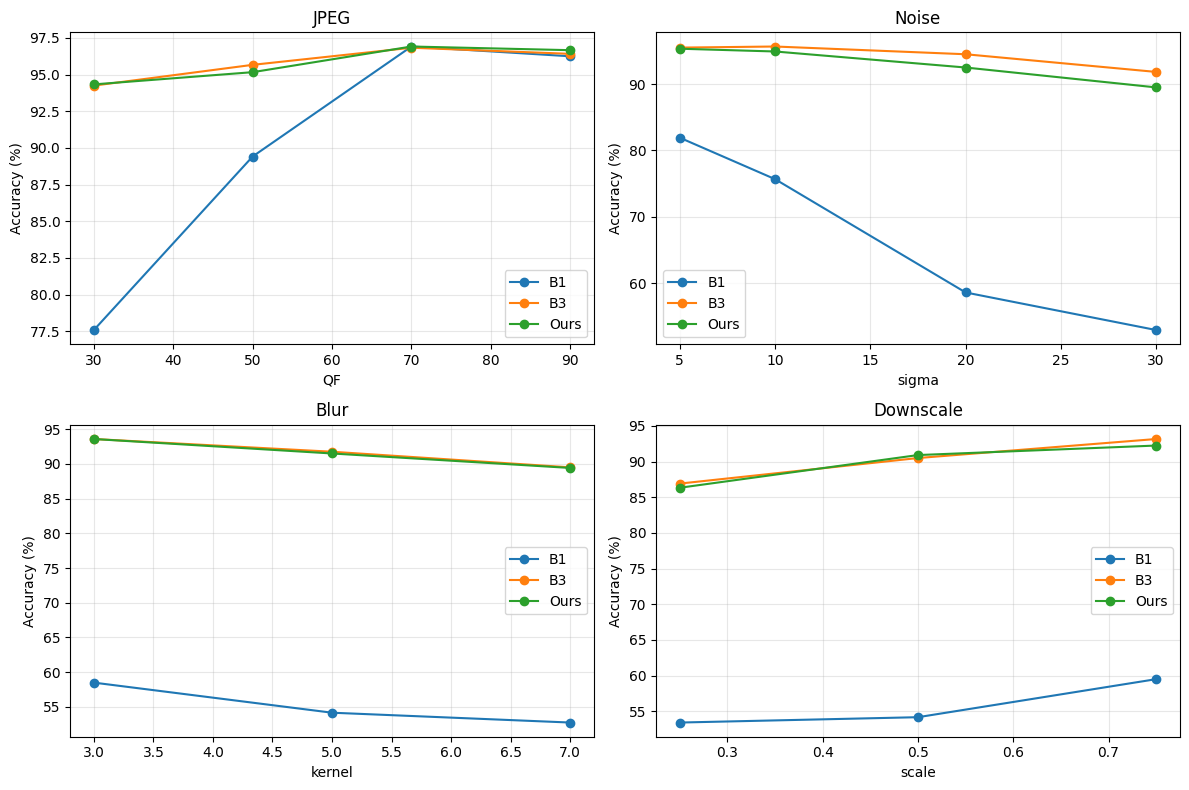

In [12]:
# ============================================================
# CELL 12: PERFORMANCE DEGRADATION CURVES (Section 5.3.3)
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, dtype in zip(axes.ravel(), CONFIG['degradations'].keys()):
    for name in ['B1', 'B3', 'Ours']:
        sub = df_rob[(df_rob.model==name) & (df_rob.degradation==dtype)].sort_values('level')
        ax.plot(sub['level'], sub['acc'], marker='o', label=name)
    ax.set_title(dtype); ax.set_xlabel(CONFIG['degradations'][dtype]['param_name'])
    ax.set_ylabel('Accuracy (%)'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['output_dir'], 'fig_degradation_curves.png'), dpi=130)
plt.show()

In [13]:
# ============================================================
# CELL 13: GENERALIZATION on Artistic + Custom (Section 5.3.4)
# ============================================================
# Requires CONFIG['artistic_dir'] / ['custom_dir'] to point to folders with
# subfolders FAKE/ and REAL/. Skipped if not set.
def load_folder(root):
    imgs, lbls = [], []
    for cls, cid in [('FAKE', FAKE_ID), ('REAL', REAL_ID)]:
        d = os.path.join(root, cls)
        if not os.path.isdir(d): continue
        for fn in os.listdir(d):
            try:
                imgs.append(Image.open(os.path.join(d, fn)).convert('RGB')); lbls.append(cid)
            except Exception:
                pass
    return imgs, np.asarray(lbls, int)

for name, path in [('Artistic', CONFIG['artistic_dir']), ('Custom', CONFIG['custom_dir'])]:
    if not path or not os.path.isdir(path):
        print(f'[SKIP] {name}: set CONFIG["{name.lower()}_dir"] to a FAKE/REAL folder to enable.')
        continue
    gi, gl = load_folder(path)
    print(f'{name}: {len(gi)} images')
    for tag in ['B1', 'B3', 'Ours']:
        pred = predict(seed_models[tag], gi, gl)[0]
        print(f'  {tag}: acc={accuracy_score(gl, pred)*100:.2f}%')

[SKIP] Artistic: set CONFIG["artistic_dir"] to a FAKE/REAL folder to enable.
[SKIP] Custom: set CONFIG["custom_dir"] to a FAKE/REAL folder to enable.


In [14]:
# ============================================================
# CELL 14: ABLATION (Section 5.3.5) + SAVE ARTIFACTS
# ============================================================
# Reuse the seed-42 B1/B3/Ours from Cell 9; train only the missing
# edge-only-no-aug variant at seed 42. Single representative seed.
model_edge_noaug = train_model(use_edge=True, augment=False,
                               tag='abl_edge_noaug', seed=CONFIG['seed'])

abl = []
for tag, mdl in [('Ours (edge + aug)',        seed_models['Ours']),
                 ('-- aug (edge only)',        model_edge_noaug),
                 ('-- edge (aug only) = B3',    seed_models['B3']),
                 ('-- both (plain) = B1',       seed_models['B1'])]:
    m = evaluate(mdl, imgs_test, gt_test)
    abl.append([tag, m['acc'], m['f1'], m['auc']])
df_abl = pd.DataFrame(abl, columns=['Variant', 'Accuracy (%)', 'F1 (%)', 'AUC-ROC (%)'])
print(df_abl.to_string(index=False))
df_abl.to_csv(os.path.join(CONFIG['output_dir'], 'table_ablation.csv'), index=False)
del model_edge_noaug; free_mem()

# Backup all CSV/PNG/PT to Drive
import shutil
for f in os.listdir(CONFIG['output_dir']):
    shutil.copy(os.path.join(CONFIG['output_dir'], f),
                os.path.join(CONFIG['drive_backup'], f))
print('[OK] Notebook 04 complete. Artifacts backed up to', CONFIG['drive_backup'])


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

abl_edge_noaug ep1:   0%|          | 0/175 [00:00<?, ?it/s]

  abl_edge_noaug epoch 1: val acc=94.50% f1=94.65%


abl_edge_noaug ep2:   0%|          | 0/175 [00:00<?, ?it/s]

  abl_edge_noaug epoch 2: val acc=96.08% f1=96.10%


...

  abl_edge_noaug epoch 3: val acc=96.33% f1=96.33%


abl_edge_noaug ep4:   0%|          | 0/175 [00:00<?, ?it/s]

  abl_edge_noaug epoch 4: val acc=96.17% f1=96.26%


abl_edge_noaug ep5:   0%|          | 0/175 [00:00<?, ?it/s]

  abl_edge_noaug epoch 5: val acc=96.83% f1=96.82%
[OK] abl_edge_noaug trained. best val F1=96.82%
                Variant  Accuracy (%)    F1 (%)  AUC-ROC (%)
      Ours (edge + aug)     96.833333 96.843854    99.523889
     -- aug (edge only)     97.000000 96.969697    99.561250
-- edge (aug only) = B3     96.750000 96.774194    99.586389
   -- both (plain) = B1     97.000000 96.969697    99.679722
[OK] Notebook 04 complete. Artifacts backed up to /content/drive/MyDrive/luanvan_thac_si/notebook04_artifacts
